# Reto avanzado 3 — Estabilidad de clusters (Jackknife Clustering)

Objetivo: comprobar que la segmentación es **robusta** antes de basar decisiones de marketing en ella. Si se elimina un subconjunto aleatorio de clientes y se reentrena el modelo, ¿se mantienen los mismos segmentos?

Pasos, en el orden del enunciado:

1. Generar **20 submuestras**, cada una excluyendo un **20 %** aleatorio de los clientes, y entrenar K-Means con el mismo k = 5 sobre cada una.
2. Medir la estabilidad de las asignaciones de los clientes presentes en varias submuestras (% de coincidencia).
3. Análisis por cluster: ¿hay algún segmento inestable? ¿Qué clientes "saltan" entre clusters?
4. Recomendación final.

> Requisito: ejecutar antes `notebooks-básico/02_feature_engineering.ipynb` y `03_kmeans.ipynb`, que generan `data/processed/`.

## Resumen

**Qué se hizo:** 20 reentrenamientos de K-Means (k = 5), cada uno sin un 20 % aleatorio de los clientes, comparando las asignaciones con los segmentos del Reto 3.

**Resultados clave**
- **ARI entre 0,991 y 0,997** en las 20 ejecuciones: cada reentrenamiento reproduce prácticamente los mismos segmentos (sección 3).
- El **99,3 %** de los clientes cae en su mismo segmento en **todas** las ejecuciones en que aparece; la coincidencia media es del 99,8 % (sección 4).
- Solo un **0,3 %** de los clientes "salta" (coincidencia < 80 %). Ningún segmento es inestable: el que más clientes pierde no llega al 0,4 % (sección 5).
- Los saltos se concentran entre **Fieles Acomodados y Candidatos a Renovación**, y los clientes que saltan están **en la frontera** entre dos centroides (sección 6).

**Recomendación:** la segmentación es **fiable** para basar decisiones de marketing en ella. Los pocos clientes frontera pueden tratarse con la acción de cualquiera de sus dos segmentos posibles.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_colwidth", None)

PROCESSED = next(p for p in (Path("data/processed"), Path("../data/processed")) if p.exists())

X = pd.read_csv(PROCESSED / "X_model.csv", index_col="client_id")
X_np = X.to_numpy()
K = 5

# Reference: final K-Means model of the Reto 3
reference = pd.read_csv(PROCESSED / "clusters.csv", index_col="client_id")["cluster"].loc[X.index].to_numpy()

# Segment names: same rules as notebooks-básico/04_segmentos.ipynb
clients = pd.read_csv(PROCESSED / "client_features.csv", index_col="client_id").loc[X.index]
means = clients.groupby(reference)[["n_current_vehicles", "consent_level", "pct_plugin", "months_as_mb_customer"]].mean()
names = {}
names[means["n_current_vehicles"].idxmin()] = "Clientes Perdidos"
names[means["consent_level"].drop(list(names)).idxmin()] = "Clientes Silenciosos"
names[means["pct_plugin"].drop(list(names)).idxmax()] = "Pioneros Eléctricos"
names[means["months_as_mb_customer"].drop(list(names)).idxmax()] = "Fieles Acomodados"
names[means.index.difference(list(names))[0]] = "Candidatos a Renovación"
ORDER = ["Fieles Acomodados", "Candidatos a Renovación", "Pioneros Eléctricos", "Clientes Silenciosos", "Clientes Perdidos"]
CLUSTER_ORDER = [k for name in ORDER for k, v in names.items() if v == name]
PALETTE = dict(zip(ORDER, sns.color_palette("tab10", len(ORDER))))

reference_centroids = np.vstack([X_np[reference == k].mean(axis=0) for k in range(K)])
print(f"Matriz: {X.shape[0]:,} clientes × {X.shape[1]} features | k = {K}")

Matriz: 173,454 clientes × 19 features | k = 5


## 1. Jackknife: 20 submuestras sin el 20 % de los clientes

| Parámetro | Valor | Motivo |
|---|---|---|
| Nº de submuestras | 20 | Valor propuesto en el enunciado |
| % excluido en cada una | **20 %** (~34.700 clientes) | Extremo superior del rango del enunciado (10–20 %): la prueba más exigente. Si aguanta con un 20 %, aguanta con menos |
| Modelo | K-Means, k = 5, `k-means++`, `n_init=10` | La misma configuración que el Reto 3; una semilla distinta por submuestra |

**Emparejamiento de clusters.** K-Means numera los clusters de forma arbitraria: el "cluster 2" de una ejecución puede ser el "cluster 4" de otra. Antes de comparar, cada cluster de cada ejecución se empareja con el segmento de referencia (Reto 3) cuyo **centroide está más cerca**, con una asignación uno a uno (algoritmo húngaro, `linear_sum_assignment`). Así, "coincidir" significa caer en el **mismo segmento de negocio**.

In [2]:
N_RUNS = 20
DROP = 0.20
rng = np.random.default_rng(42)

assigned = np.full((N_RUNS, len(X_np)), -1)  # -1 = client excluded in that run
runs = []
for run in range(N_RUNS):
    keep = np.sort(rng.choice(len(X_np), int(len(X_np) * (1 - DROP)), replace=False))
    model = KMeans(n_clusters=K, init="k-means++", n_init=10, random_state=run).fit(X_np[keep])

    # Match each new cluster to the closest reference centroid (one-to-one)
    distances = ((model.cluster_centers_[:, None, :] - reference_centroids[None, :, :]) ** 2).sum(axis=-1)
    new_ids, ref_ids = linear_sum_assignment(distances)
    mapping = dict(zip(new_ids, ref_ids))
    assigned[run, keep] = np.vectorize(mapping.get)(model.labels_)

    runs.append({
        "ejecución": run + 1,
        "clientes": len(keep),
        "ARI vs Reto 3": adjusted_rand_score(reference[keep], assigned[run, keep]),
        "coincidencia_%": (assigned[run, keep] == reference[keep]).mean() * 100,
        "iteraciones": model.n_iter_,
    })

runs = pd.DataFrame(runs).set_index("ejecución")
runs.describe().loc[["mean", "min", "max"]]

,clientes,ARI vs Reto 3,coincidencia_%,iteraciones
mean,"138,763.0000",0.9952,99.8357,32.9000
min,"138,763.0000",0.9909,99.6966,9.0000
max,"138,763.0000",0.9972,99.9027,68.0000


## 2. ¿Se reproducen los mismos segmentos en cada ejecución?

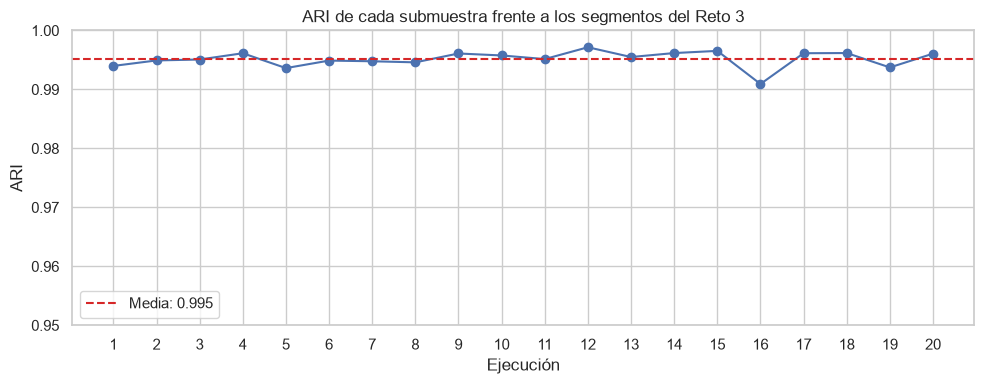

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(runs.index, runs["ARI vs Reto 3"], marker="o")
ax.axhline(runs["ARI vs Reto 3"].mean(), color="tab:red", linestyle="--", label=f"Media: {runs['ARI vs Reto 3'].mean():.3f}")
ax.set(title="ARI de cada submuestra frente a los segmentos del Reto 3", xlabel="Ejecución", ylabel="ARI", ylim=(0.95, 1.0), xticks=runs.index)
ax.legend()
plt.tight_layout()
plt.show()

**Interpretación**

- El ARI compara dos particiones (1 = idénticas, 0 = coincidencia al azar). En las 20 ejecuciones está entre **0,991 y 0,997**: quitar un 20 % de los clientes y reentrenar da prácticamente los mismos 5 segmentos.
- No hay ninguna ejecución "mala": el resultado no depende de qué clientes se excluyan.

## 3. Estabilidad de cada cliente

Para cada cliente se calcula el **% de coincidencia**: en cuántas de las ejecuciones en que estuvo presente cayó en su mismo segmento del Reto 3. Con un 20 % excluido, cada cliente aparece en unas 16 de las 20 ejecuciones.

In [4]:
present = assigned >= 0
consistency = pd.Series(((assigned == reference) & present).sum(axis=0) / present.sum(axis=0), index=X.index, name="coincidencia")
segment = pd.Series(reference, index=X.index).map(names)

JUMP_THRESHOLD = 0.8
pd.Series({
    "ejecuciones por cliente (media)": present.sum(axis=0).mean(),
    "coincidencia media (%)": consistency.mean() * 100,
    "clientes con 100 % de coincidencia (%)": (consistency == 1).mean() * 100,
    f"clientes que saltan: coincidencia < {JUMP_THRESHOLD:.0%} (%)": (consistency < JUMP_THRESHOLD).mean() * 100,
    "clientes que saltan (nº)": (consistency < JUMP_THRESHOLD).sum(),
}, name="valor").to_frame()

,valor
ejecuciones por cliente (media),16.0000
coincidencia media (%),99.8353
clientes con 100 % de coincidencia (%),99.3382
clientes que saltan: coincidencia < 80% (%),0.2986
clientes que saltan (nº),518.0000


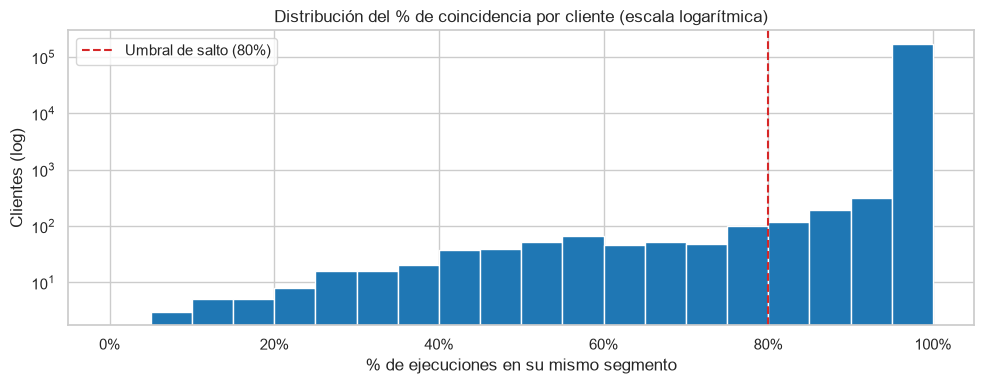

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.linspace(0, 1, 21)
ax.hist(consistency, bins=bins, color="tab:blue", edgecolor="white")
ax.axvline(JUMP_THRESHOLD, color="tab:red", linestyle="--", label=f"Umbral de salto ({JUMP_THRESHOLD:.0%})")
ax.set_yscale("log")
ax.set(title="Distribución del % de coincidencia por cliente (escala logarítmica)", xlabel="% de ejecuciones en su mismo segmento", ylabel="Clientes (log)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend()
plt.tight_layout()
plt.show()

**Interpretación**

- El eje vertical está en **escala logarítmica**: sin ella, la barra del 100 % taparía todas las demás.
- El **99,3 %** de los clientes cae en su segmento en **todas** las ejecuciones en que aparece, y la coincidencia media es del **99,8 %**.
- Solo un **0,3 %** de los clientes (unos 520) baja del 80 % de coincidencia. Son los que "saltan" entre segmentos; se analizan a continuación.

## 4. Análisis por segmento

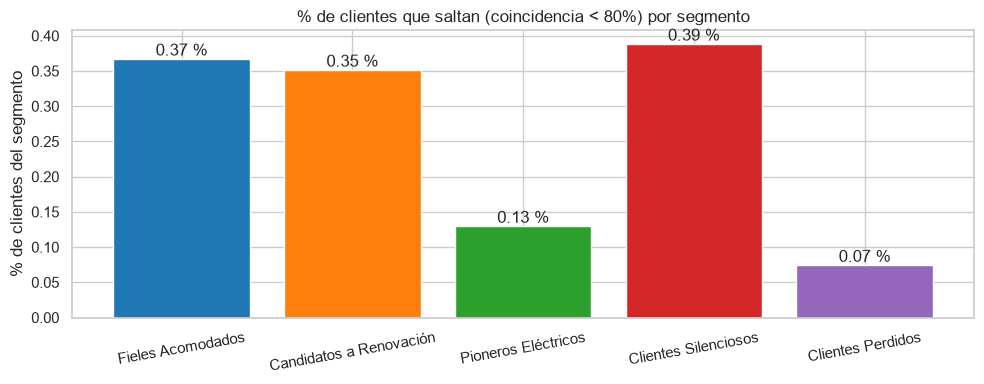

,clientes,coincidencia media (%),clientes que saltan (%),clientes que saltan (nº)
Fieles Acomodados,49610,99.8007,0.3669,182
Candidatos a Renovación,58380,99.7960,0.3511,205
Pioneros Eléctricos,26257,99.9290,0.1295,34
Clientes Silenciosos,21646,99.8058,0.3881,84
Clientes Perdidos,17561,99.9600,0.0740,13


In [6]:
by_segment = pd.DataFrame({
    "clientes": segment.value_counts(),
    "coincidencia media (%)": consistency.groupby(segment).mean() * 100,
    "clientes que saltan (%)": (consistency < JUMP_THRESHOLD).groupby(segment).mean() * 100,
    "clientes que saltan (nº)": (consistency < JUMP_THRESHOLD).groupby(segment).sum(),
}).reindex(ORDER)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(by_segment.index, by_segment["clientes que saltan (%)"], color=[PALETTE[s] for s in ORDER])
ax.bar_label(bars, fmt="%.2f %%")
ax.set(title=f"% de clientes que saltan (coincidencia < {JUMP_THRESHOLD:.0%}) por segmento", ylabel="% de clientes del segmento")
ax.tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.show()

by_segment

**Interpretación**

- **Ningún segmento es inestable**: en todos, más del 99,6 % de los clientes se mantiene en su segmento.
- **El más estable: Clientes Perdidos** (casi ningún cliente salta). Es el perfil más diferenciado — no tienen vehículo actual —, el mismo que detectaban GMM y DBSCAN en la comparativa.
- **Los menos estables: Clientes Silenciosos, Fieles Acomodados y Candidatos a Renovación** (alrededor del 0,35–0,4 %), aunque la diferencia es pequeña en valor absoluto.

## 5. ¿Entre qué segmentos saltan los clientes?

Matriz de saltos: para todas las ejecuciones, cuántas veces un cliente de un segmento (fila) fue asignado a otro segmento (columna). La diagonal (asignación correcta) se excluye para ver solo los saltos.

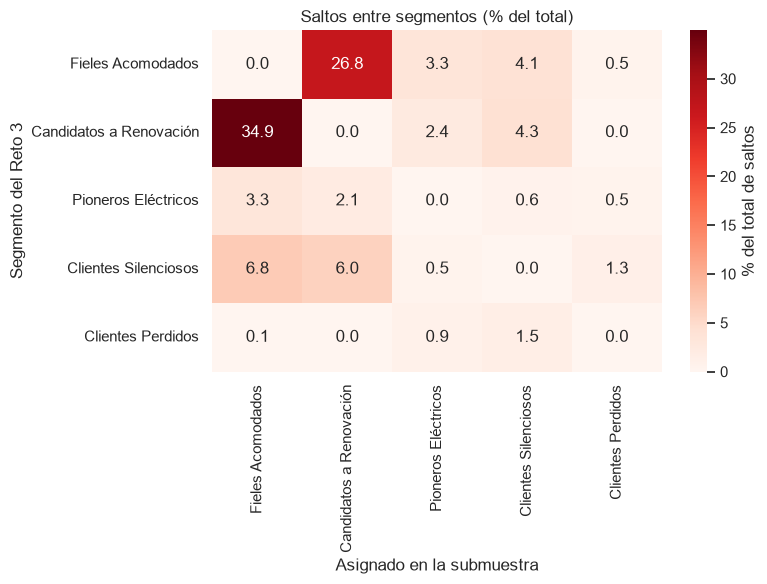

,% de los saltos
Candidatos a Renovación → Fieles Acomodados,34.9419
Fieles Acomodados → Candidatos a Renovación,26.7822
Clientes Silenciosos → Fieles Acomodados,6.8436
Clientes Silenciosos → Candidatos a Renovación,6.0320


In [7]:
jumps = np.zeros((K, K), dtype=int)
for run in range(N_RUNS):
    mask = assigned[run] >= 0
    np.add.at(jumps, (reference[mask], assigned[run][mask]), 1)
np.fill_diagonal(jumps, 0)

jumps = pd.DataFrame(jumps, index=[names[k] for k in range(K)], columns=[names[k] for k in range(K)]).loc[ORDER, ORDER]
jump_share = jumps / jumps.values.sum() * 100

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(jump_share, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "% del total de saltos"}, ax=ax)
ax.set(title="Saltos entre segmentos (% del total)", xlabel="Asignado en la submuestra", ylabel="Segmento del Reto 3")
plt.tight_layout()
plt.show()

pairs = jump_share.stack().sort_values(ascending=False).head(4).rename("% de los saltos").to_frame()
pairs.index = [f"{a} → {b}" for a, b in pairs.index]
pairs

**Interpretación**

- La mayoría de los saltos se dan **entre Fieles Acomodados y Candidatos a Renovación**, en los dos sentidos. Son los dos segmentos más grandes y, en el PCA, ocupan zonas vecinas a lo largo de PC1 (intensidad de la relación con la marca): el paso de uno a otro es gradual.
- El resto de saltos son pocos y se reparten entre segmentos vecinos; los Clientes Perdidos casi no reciben ni pierden clientes.

## 6. ¿Por qué saltan? Clientes en la frontera

Se calcula, para cada cliente, el **margen**: la diferencia entre la distancia a su segundo centroide más cercano y a su centroide asignado (Reto 3). Un margen cercano a 0 significa que el cliente está **a medio camino entre dos segmentos**, de modo que un pequeño desplazamiento de los centroides (al quitar clientes) lo cambia de lado.

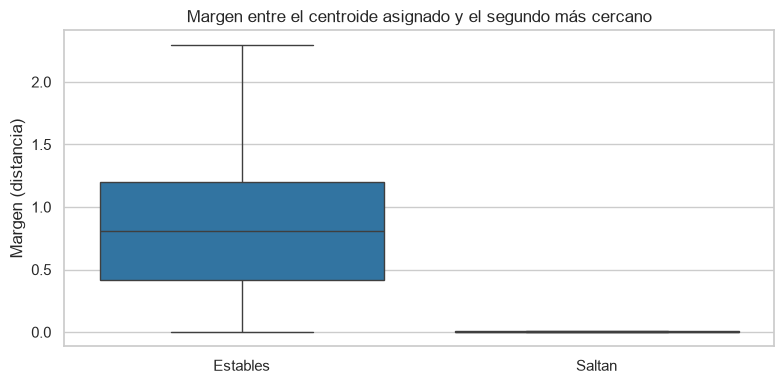

,count,25%,50%,75%
Estables,"172,936.0000",0.4172,0.8077,1.2033
Saltan,518.0000,0.0012,0.0027,0.0049


In [8]:
distances = np.sqrt(((X_np[:, None, :] - reference_centroids[None, :, :]) ** 2).sum(axis=-1))
sorted_d = np.sort(distances, axis=1)
margin = pd.Series(sorted_d[:, 1] - sorted_d[:, 0], index=X.index, name="margen")
group = np.where(consistency < JUMP_THRESHOLD, "Saltan", "Estables")

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(x=group, y=margin, hue=group, order=["Estables", "Saltan"], hue_order=["Estables", "Saltan"], palette=["tab:blue", "tab:red"], showfliers=False, ax=ax, legend=False)
ax.set(title="Margen entre el centroide asignado y el segundo más cercano", xlabel="", ylabel="Margen (distancia)")
plt.tight_layout()
plt.show()

margin.groupby(group).describe()[["count", "25%", "50%", "75%"]]

**Interpretación**

- Los clientes que saltan tienen un margen **prácticamente nulo** (mediana ≈ 0,003, frente a ≈ 0,8 en los estables): están justo en la frontera entre dos segmentos.
- No es un fallo del modelo: con clientes que forman un **continuo** (Silhouette ~0,14, Reto 3), siempre habrá una franja de clientes frontera. Lo importante es que esa franja es **muy estrecha** (0,3 %).

## Conclusiones y recomendación final

- **La segmentación es estable:** quitando el 20 % de los clientes 20 veces, se obtienen los mismos 5 segmentos (ARI 0,991–0,997) y el 99,3 % de los clientes no cambia nunca de segmento.
- **Cluster más estable: Clientes Perdidos**, el perfil más diferenciado (sin vehículo actual).
- **Clusters menos estables: Fieles Acomodados y Candidatos a Renovación** (también Clientes Silenciosos), porque comparten frontera: la diferencia entre ellos es gradual. Aun así, menos del 0,4 % de sus clientes salta.
- **Los clientes que saltan** (~0,3 %) están en la frontera entre dos centroides (margen ≈ 0).

**Recomendación:**

1. **Usar la segmentación de K-Means (k = 5) para las decisiones de marketing**: es reproducible tanto frente a la inicialización (5 semillas, Reto 3) como frente a los datos (jackknife).
2. **Tratar a los clientes frontera** (coincidencia < 80 %) como un caso especial: pueden recibir la acción de cualquiera de sus dos segmentos posibles o priorizarse según el objetivo de la campaña (p. ej., un cliente entre Fieles Acomodados y Candidatos a Renovación encaja tanto en una renovación anticipada como en una oferta de renovación).
3. **Reentrenar periódicamente** con los mismos parámetros cuando entren datos nuevos y repetir esta comprobación: si la estabilidad se mantiene, los segmentos siguen siendo válidos.